# Notebook 03 — PCA e clusterização

Resume a variação dos espectros com PCA, escolhe o número de grupos (cotovelo e silhueta)
e agrupa as amostras com k-means sobre os primeiros componentes.

**Entradas:** `espectros_pp.npz`, `df_pp.pkl` · **Saídas:** `df_pp.pkl` (com a coluna `cluster`), `cluster_model.joblib`, figuras `03_*.png`

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as cfg, utils

cfg.PASTA_FIG.mkdir(parents=True, exist_ok=True)
import joblib
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

d = np.load(cfg.PASTA / 'espectros_pp.npz')
X_snv, wl, y = d['X_snv'], d['wl'], d['y']
df = pd.read_pickle(cfg.PASTA / 'df_pp.pkl')
print('Amostras:', X_snv.shape[0], '| bandas:', X_snv.shape[1])

Amostras: 844 | bandas: 401


## 1. Análise de componentes principais

In [2]:
pca = PCA(n_components=cfg.N_PCS_EXPLORA).fit(X_snv)
scores = pca.transform(X_snv)
var = pca.explained_variance_ratio_
print('Variância explicada (%):', (100 * var).round(1))
print('Acumulada (%):         ', (100 * var.cumsum()).round(1))

Variância explicada (%): [96.1  0.2  0.2  0.1  0.1  0.1  0.1  0.1  0.1  0.1]
Acumulada (%):          [96.1 96.3 96.5 96.6 96.7 96.8 96.9 97.  97.1 97.2]


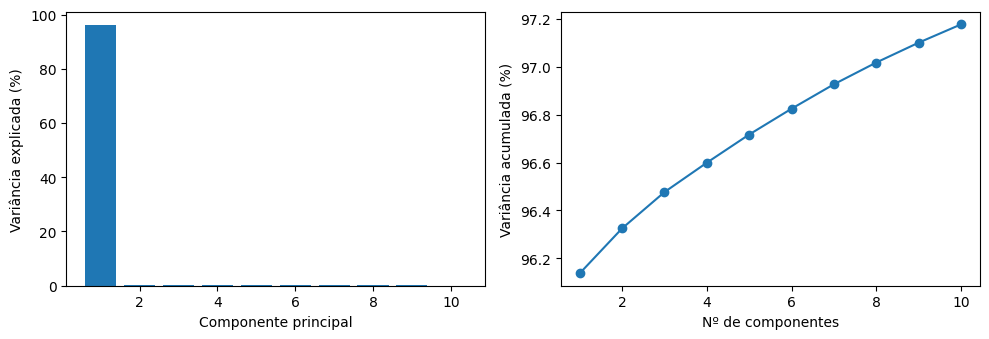

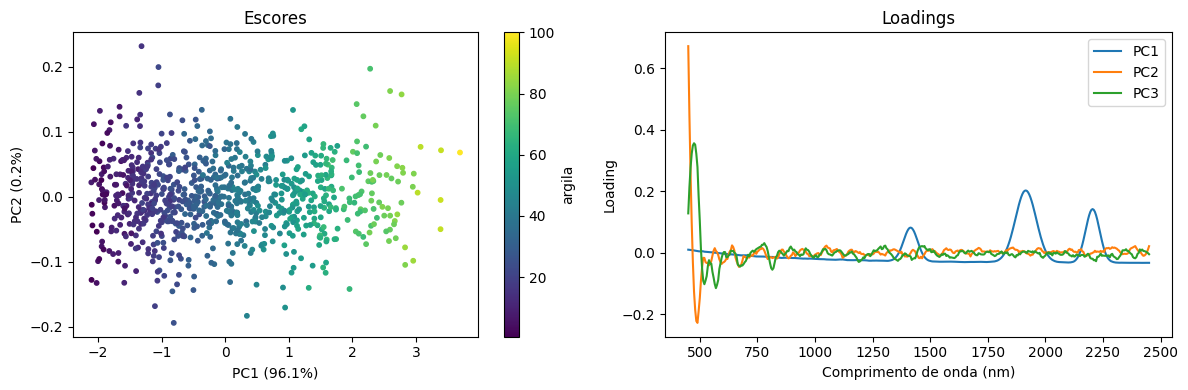

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(range(1, len(var) + 1), 100 * var)
ax[0].set_xlabel('Componente principal'); ax[0].set_ylabel('Variância explicada (%)')
ax[1].plot(range(1, len(var) + 1), 100 * var.cumsum(), 'o-')
ax[1].set_xlabel('Nº de componentes'); ax[1].set_ylabel('Variância acumulada (%)')
plt.tight_layout(); utils.salva_figura(fig, '03_variancia_pca.png'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sc = ax[0].scatter(scores[:, 0], scores[:, 1], c=y, cmap='viridis', s=10)
plt.colorbar(sc, ax=ax[0], label=cfg.COL_ALVO)
ax[0].set_xlabel(f'PC1 ({100 * var[0]:.1f}%)'); ax[0].set_ylabel(f'PC2 ({100 * var[1]:.1f}%)')
ax[0].set_title('Escores')
for i in range(3):
    ax[1].plot(wl, pca.components_[i], label=f'PC{i + 1}')
ax[1].set_xlabel('Comprimento de onda (nm)'); ax[1].set_ylabel('Loading'); ax[1].legend()
ax[1].set_title('Loadings')
plt.tight_layout(); utils.salva_figura(fig, '03_escores_loadings.png'); plt.show()

## 2. Número de grupos: cotovelo e silhueta

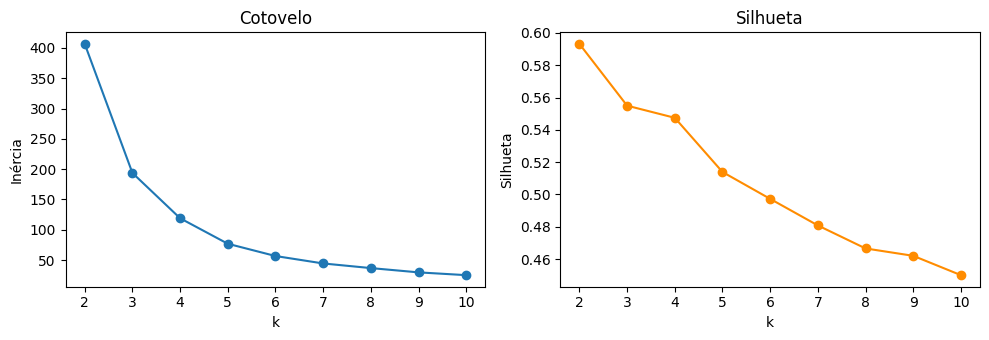

,k,inercia,silhueta
0,2,406.560,0.593
1,3,193.734,0.555
2,4,119.043,0.547
3,5,76.996,0.514
4,6,56.757,0.497
5,7,44.498,0.481
6,8,36.864,0.467
7,9,29.802,0.462
8,10,25.205,0.450


In [4]:
pca_cl = PCA(n_components=cfg.N_PCS_CLUSTER).fit(X_snv)
Zc = pca_cl.transform(X_snv)

ks = range(2, cfg.K_MAX + 1)
inercia, silhueta = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=cfg.SEED).fit(Zc)
    inercia.append(km_k.inertia_)
    silhueta.append(silhouette_score(Zc, km_k.labels_, sample_size=min(5000, len(Zc)), random_state=cfg.SEED))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(list(ks), inercia, 'o-'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inércia'); ax[0].set_title('Cotovelo')
ax[1].plot(list(ks), silhueta, 'o-', color='darkorange'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhueta')
ax[1].set_title('Silhueta')
plt.tight_layout(); utils.salva_figura(fig, '03_cotovelo_silhueta.png'); plt.show()
display(pd.DataFrame({'k': list(ks), 'inercia': inercia, 'silhueta': silhueta}).round(3))

## 3. K-means final e caracterização dos grupos

In [5]:
km = KMeans(n_clusters=cfg.K, n_init=10, random_state=cfg.SEED).fit(Zc)
df['cluster'] = km.labels_
print('Amostras por grupo:'); print(df['cluster'].value_counts().sort_index())
display(df.groupby('cluster')[cfg.COL_ALVO].describe().round(1))

Amostras por grupo:
cluster
0    300
1    320
2    224
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,300.0,38.3,7.1,22.8,33.0,38.3,43.6,54.7
1,320.0,15.7,7.2,0.5,10.4,15.8,21.0,33.7
2,224.0,64.8,10.4,46.8,56.8,62.7,71.7,100.0


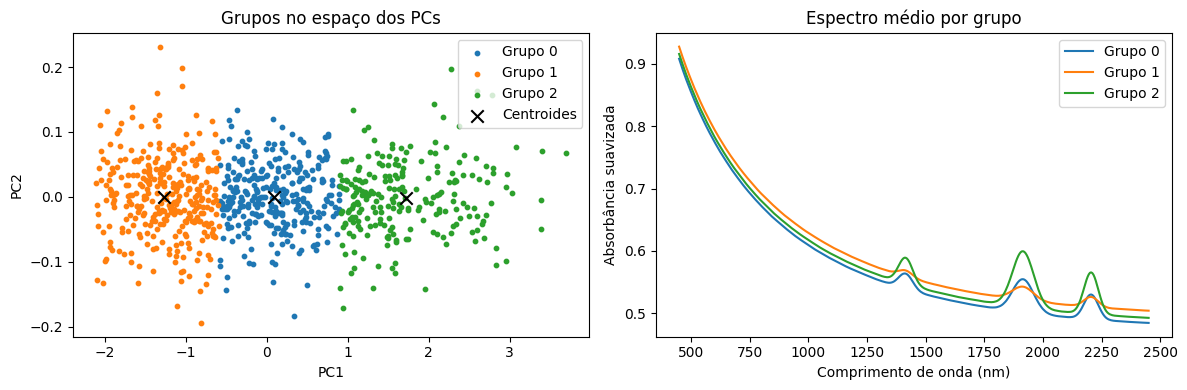

Salvos: df_pp.pkl (com cluster) e cluster_model.joblib


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for g in range(cfg.K):
    sel = km.labels_ == g
    ax[0].scatter(Zc[sel, 0], Zc[sel, 1], s=10, label=f'Grupo {g}')
    ax[1].plot(wl, d['X_suav'][sel].mean(axis=0), label=f'Grupo {g}')
ax[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='black', marker='x', s=80, label='Centroides')
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend(); ax[0].set_title('Grupos no espaço dos PCs')
ax[1].set_xlabel('Comprimento de onda (nm)'); ax[1].set_ylabel('Absorbância suavizada'); ax[1].legend()
ax[1].set_title('Espectro médio por grupo')
plt.tight_layout(); utils.salva_figura(fig, '03_clusters.png'); plt.show()

df.to_pickle(cfg.PASTA / 'df_pp.pkl')
joblib.dump({'km': km, 'pca': pca_cl, 'n_pcs': cfg.N_PCS_CLUSTER}, cfg.PASTA / 'cluster_model.joblib')
print('Salvos: df_pp.pkl (com cluster) e cluster_model.joblib')